In [9]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from IPython.display import display


RAIZ = Path.cwd().resolve()

if not (RAIZ / "laboratorio.py").exists():
    RAIZ = RAIZ.parent


ARQUIVO = (
    RAIZ
    / "datasets"
    / "dataset_experimental.csv"
)

dataset = pd.read_csv(ARQUIVO)

print("Linhas:", len(dataset))
print("Ensaios:", dataset["ensaio"].nunique())

Linhas: 2160
Ensaios: 12


In [10]:
COLUNAS_ML = [
    "taxa_requisicoes",
    "latencia_ms",
    "latencia_disponivel"
]

COLUNAS_CONTINUAS = [
    "taxa_requisicoes",
    "latencia_ms"
]

COLUNAS_AVALIACAO = [
    "label",
    "condicao",
    "nivel_carga",
    "manutencao_legitima",
    "janela_transicao",
    "seed",
    "ensaio",
    "janela"
]
X_treino = dataset.loc[
    dataset["split"] == "treino",
    COLUNAS_ML
].copy()

X_validacao = dataset.loc[
    dataset["split"] == "validacao",
    COLUNAS_ML
].copy()

X_teste = dataset.loc[
    dataset["split"] == "teste",
    COLUNAS_ML
].copy()


avaliacao_treino = dataset.loc[
    dataset["split"] == "treino",
    COLUNAS_AVALIACAO
].copy()

avaliacao_validacao = dataset.loc[
    dataset["split"] == "validacao",
    COLUNAS_AVALIACAO
].copy()

avaliacao_teste = dataset.loc[
    dataset["split"] == "teste",
    COLUNAS_AVALIACAO
].copy()


print("Treino:", X_treino.shape)
print("Validação:", X_validacao.shape)
print("Teste:", X_teste.shape)

Treino: (1080, 3)
Validação: (540, 3)
Teste: (540, 3)


In [11]:
mediana_latencia_treino = (
    X_treino["latencia_ms"].median()
)

print(
    "Mediana da latência:",
    round(mediana_latencia_treino, 4)
)


for X in [
    X_treino,
    X_validacao,
    X_teste
]:
    X["latencia_ms"] = (
        X["latencia_ms"]
        .fillna(
            mediana_latencia_treino
        )
    )

print(
    "NaN treino:",
    X_treino.isna().sum().sum()
)

print(
    "NaN validação:",
    X_validacao.isna().sum().sum()
)

print(
    "NaN teste:",
    X_teste.isna().sum().sum()
)

Mediana da latência: 2.4758
NaN treino: 0
NaN validação: 0
NaN teste: 0


In [12]:
standard_scaler = StandardScaler()

standard_scaler.fit(
    X_treino[
        COLUNAS_CONTINUAS
    ]
)

StandardScaler()

In [13]:
def transformar_dados(
    X,
    scaler
):
    X_transformado = X.copy()

    X_transformado[
        COLUNAS_CONTINUAS
    ] = scaler.transform(
        X[
            COLUNAS_CONTINUAS
        ]
    )

    return X_transformado

In [14]:
X_treino_standard = transformar_dados(
    X_treino,
    standard_scaler
)

X_validacao_standard = transformar_dados(
    X_validacao,
    standard_scaler
)

X_teste_standard = transformar_dados(
    X_teste,
    standard_scaler
)
display(
    X_treino_standard.head()
)

,taxa_requisicoes,latencia_ms,latencia_disponivel
0,-0.669093,-2.355384,1
1,-0.365853,-0.656346,1
2,-0.972333,0.083042,0
3,-0.669093,1.951407,1
4,-0.669093,-1.988158,1


In [15]:
from sklearn.cluster import KMeans

K_PRINCIPAL = 5

kmeans = KMeans(
    n_clusters=K_PRINCIPAL,
    random_state=42,
    n_init=20
)

clusters_treino = kmeans.fit_predict(
    X_treino_standard
)

clusters_validacao = kmeans.predict(
    X_validacao_standard
)

clusters_teste = kmeans.predict(
    X_teste_standard
)

print(
    "Clusters encontrados:",
    sorted(set(clusters_treino))
)

Clusters encontrados: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4)]


In [16]:
contagem_clusters = pd.Series(
    clusters_treino
).value_counts().sort_index()

display(
    contagem_clusters.rename(
        "quantidade"
    )
)

0    375
1    119
2    188
3    187
4    211
Name: quantidade, dtype: int64

In [17]:
percentual_clusters = (
    contagem_clusters
    / len(clusters_treino)
    * 100
)

display(
    percentual_clusters
    .round(2)
    .rename("percentual")
)

0    34.72
1    11.02
2    17.41
3    17.31
4    19.54
Name: percentual, dtype: float64

In [18]:
centroides_normalizados = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=COLUNAS_ML
)

centroides_normalizados.index.name = (
    "cluster"
)

display(
    centroides_normalizados.round(3)
)

,taxa_requisicoes,latencia_ms,latencia_disponivel
cluster,,,
0,-0.622,0.132,0.811
1,2.361,-0.156,0.933
2,0.671,0.038,0.952
3,-0.419,1.331,1.000
4,-0.451,-1.368,1.000


In [19]:
centroides_originais = (
    centroides_normalizados.copy()
)

centroides_originais[
    COLUNAS_CONTINUAS
] = standard_scaler.inverse_transform(
    centroides_normalizados[
        COLUNAS_CONTINUAS
    ]
)

display(
    centroides_originais.round(3)
)

,taxa_requisicoes,latencia_ms,latencia_disponivel
cluster,,,
0,1.154,2.509,0.811
1,10.992,2.316,0.933
2,5.420,2.446,0.952
3,1.824,3.310,1.000
4,1.719,1.506,1.000


In [20]:
resultado_treino = (
    avaliacao_treino.copy()
)

resultado_treino[
    "cluster"
] = clusters_treino

tabela_cluster_condicao = pd.crosstab(
    resultado_treino["cluster"],
    resultado_treino["condicao"]
)

display(
    tabela_cluster_condicao
)

condicao,carga_alta,carga_baixa,carga_media,manutencao,normal,recuperacao
cluster,,,,,,
0,1,46,0,2,139,187
1,119,0,0,0,0,0
2,0,12,95,81,0,0
3,1,28,14,4,58,82
4,5,34,11,3,73,85


In [21]:
tabela_percentual = pd.crosstab(
    resultado_treino["cluster"],
    resultado_treino["condicao"],
    normalize="index"
) * 100

display(
    tabela_percentual.round(2)
)

condicao,carga_alta,carga_baixa,carga_media,manutencao,normal,recuperacao
cluster,,,,,,
0,0.27,12.27,0.00,0.53,37.07,49.87
1,100.00,0.00,0.00,0.00,0.00,0.00
2,0.00,6.38,50.53,43.09,0.00,0.00
3,0.53,14.97,7.49,2.14,31.02,43.85
4,2.37,16.11,5.21,1.42,34.60,40.28


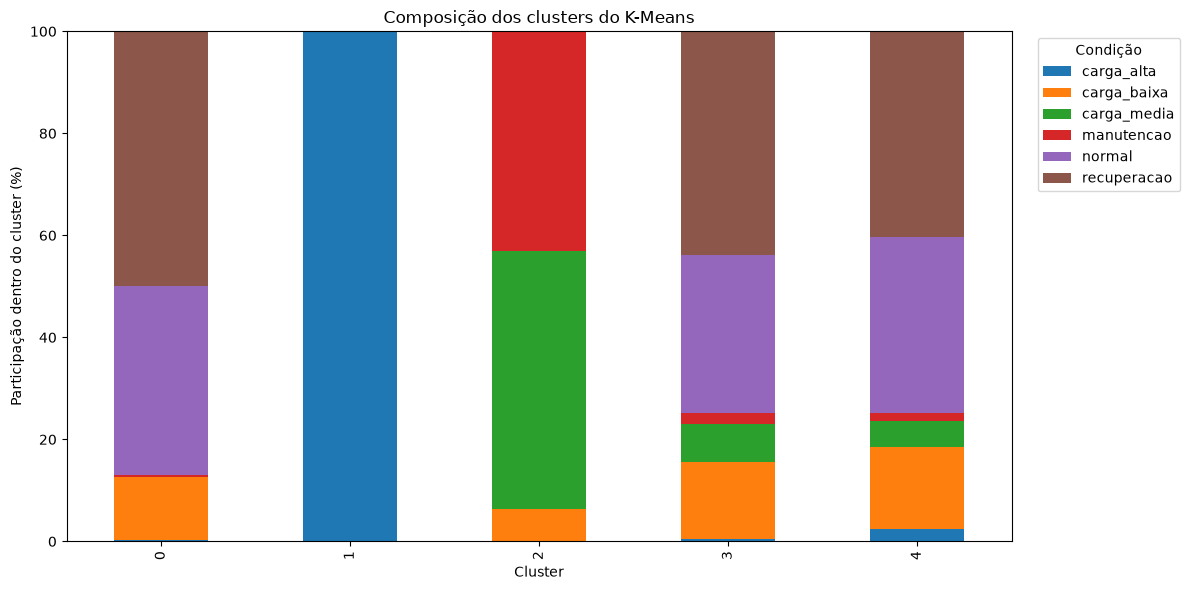

In [22]:
tabela_percentual.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title(
    "Composição dos clusters do K-Means"
)

plt.xlabel("Cluster")

plt.ylabel(
    "Participação dentro do cluster (%)"
)

plt.legend(
    title="Condição",
    bbox_to_anchor=(1.02, 1)
)

plt.tight_layout()

plt.show()

In [23]:
ataque_cluster = pd.crosstab(
    resultado_treino["cluster"],
    resultado_treino["label"]
)

display(ataque_cluster)

label,0,1
cluster,,
0,328,47
1,0,119
2,81,107
3,144,43
4,161,50


In [24]:
ataque_cluster_percentual = pd.crosstab(
    resultado_treino["cluster"],
    resultado_treino["label"],
    normalize="index"
) * 100

display(
    ataque_cluster_percentual.round(2)
)

label,0,1
cluster,,
0,87.47,12.53
1,0.00,100.00
2,43.09,56.91
3,77.01,22.99
4,76.30,23.70


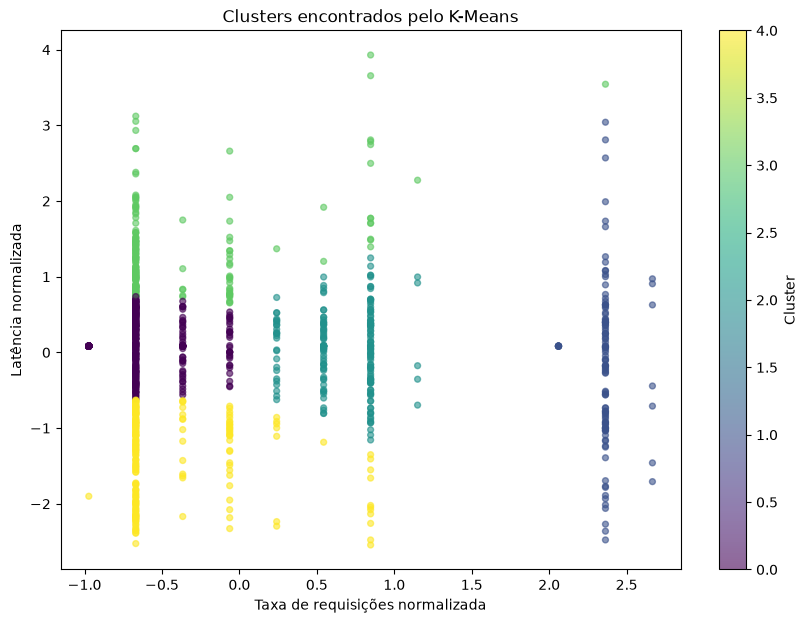

In [25]:
fig, ax = plt.subplots(
    figsize=(10, 7)
)

scatter = ax.scatter(
    X_treino_standard[
        "taxa_requisicoes"
    ],
    X_treino_standard[
        "latencia_ms"
    ],
    c=clusters_treino,
    alpha=0.6,
    s=18
)

ax.set_xlabel(
    "Taxa de requisições normalizada"
)

ax.set_ylabel(
    "Latência normalizada"
)

ax.set_title(
    "Clusters encontrados pelo K-Means"
)

plt.colorbar(
    scatter,
    ax=ax,
    label="Cluster"
)

plt.show()

In [26]:
silhouette_k5 = silhouette_score(
    X_treino_standard,
    clusters_treino
)

print(
    "Silhouette K=5:",
    round(silhouette_k5, 4)
)

Silhouette K=5: 0.4101


In [27]:
kmeans_k7 = KMeans(
    n_clusters=7,
    random_state=42,
    n_init=20
)

clusters_k7 = kmeans_k7.fit_predict(
    X_treino_standard
)

print(
    "Silhouette K=7:",
    round(
        silhouette_score(
            X_treino_standard,
            clusters_k7
        ),
        4
    )
)

Silhouette K=7: 0.4836


In [28]:
resultado_validacao = (
    avaliacao_validacao.copy()
)

resultado_validacao[
    "cluster"
] = clusters_validacao

tabela_validacao = pd.crosstab(
    resultado_validacao["cluster"],
    resultado_validacao["label"]
)

display(tabela_validacao)

label,0,1
cluster,,
0,169,23
1,0,60
2,41,54
3,66,18
4,81,28


In [29]:
percentual_validacao = pd.crosstab(
    resultado_validacao["cluster"],
    resultado_validacao["label"],
    normalize="index"
) * 100

display(
    percentual_validacao.round(2)
)

label,0,1
cluster,,
0,88.02,11.98
1,0.00,100.00
2,43.16,56.84
3,78.57,21.43
4,74.31,25.69


In [30]:
proporcao_ataque = (
    resultado_validacao
    .groupby("cluster")["label"]
    .mean()
)

display(
    (
        proporcao_ataque * 100
    )
    .round(2)
    .rename("percentual_ataque")
)

cluster
0     11.98
1    100.00
2     56.84
3     21.43
4     25.69
Name: percentual_ataque, dtype: float64

In [31]:
MAPA_CLUSTER = {}

for cluster, proporcao in (
    proporcao_ataque.items()
):

    MAPA_CLUSTER[cluster] = int(
        proporcao > 0.50
    )

print(MAPA_CLUSTER)

{0: 0, 1: 1, 2: 1, 3: 0, 4: 0}


In [32]:
resultado_validacao[
    "previsao"
] = (
    resultado_validacao[
        "cluster"
    ]
    .map(MAPA_CLUSTER)
)

In [33]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

In [34]:
y_validacao = (
    resultado_validacao["label"]
)

pred_validacao = (
    resultado_validacao["previsao"]
)

print(
    "Acurácia:",
    round(
        accuracy_score(
            y_validacao,
            pred_validacao
        ),
        4
    )
)

print(
    "Precisão:",
    round(
        precision_score(
            y_validacao,
            pred_validacao
        ),
        4
    )
)

print(
    "Recall:",
    round(
        recall_score(
            y_validacao,
            pred_validacao
        ),
        4
    )
)

print(
    "F1:",
    round(
        f1_score(
            y_validacao,
            pred_validacao
        ),
        4
    )
)

Acurácia: 0.7963
Precisão: 0.7355
Recall: 0.623
F1: 0.6746


In [35]:
matriz = confusion_matrix(
    y_validacao,
    pred_validacao
)

display(
    pd.DataFrame(
        matriz,
        index=[
            "Real legítimo",
            "Real ataque"
        ],
        columns=[
            "Previsto legítimo",
            "Previsto ataque"
        ]
    )
)

,Previsto legítimo,Previsto ataque
Real legítimo,316,41
Real ataque,69,114


In [36]:
ataques_validacao = resultado_validacao[
    resultado_validacao["label"] == 1
].copy()

recall_por_nivel = (
    ataques_validacao
    .groupby("nivel_carga")
    .agg(
        total=("label", "size"),
        detectados=("previsao", "sum")
    )
)

recall_por_nivel[
    "recall"
] = (
    recall_por_nivel["detectados"]
    / recall_por_nivel["total"]
)

display(
    recall_por_nivel.round(4)
)

,total,detectados,recall
nivel_carga,,,
alta,63,60,0.9524
baixa,60,4,0.0667
media,60,50,0.8333


In [37]:
legitimos_validacao = resultado_validacao[
    resultado_validacao["label"] == 0
].copy()

legitimos_validacao[
    "falso_positivo"
] = (
    legitimos_validacao["previsao"] == 1
).astype(int)

falsos_por_condicao = (
    legitimos_validacao
    .groupby("condicao")
    .agg(
        total=("label", "size"),
        falsos_positivos=(
            "falso_positivo",
            "sum"
        )
    )
)

falsos_por_condicao[
    "taxa_falso_positivo"
] = (
    falsos_por_condicao[
        "falsos_positivos"
    ]
    / falsos_por_condicao["total"]
)

display(
    falsos_por_condicao.round(4)
)

,total,falsos_positivos,taxa_falso_positivo
condicao,,,
manutencao,45,41,0.9111
normal,135,0,0.0000
recuperacao,177,0,0.0000


In [39]:
resultado_teste = (
    avaliacao_teste.copy()
)

resultado_teste[
    "cluster"
] = clusters_teste

resultado_teste[
    "previsao"
] = (
    resultado_teste[
        "cluster"
    ].map(MAPA_CLUSTER)
)

In [40]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

y_teste = resultado_teste["label"]

pred_teste = resultado_teste[
    "previsao"
]


metricas_teste = {
    "acuracia": accuracy_score(
        y_teste,
        pred_teste
    ),

    "precisao": precision_score(
        y_teste,
        pred_teste
    ),

    "recall": recall_score(
        y_teste,
        pred_teste
    ),

    "f1": f1_score(
        y_teste,
        pred_teste
    )
}


for nome, valor in metricas_teste.items():
    print(
        f"{nome}: {valor:.4f}"
    )

acuracia: 0.7796
precisao: 0.7254
recall: 0.5628
f1: 0.6338


In [41]:
matriz_teste = confusion_matrix(
    y_teste,
    pred_teste
)

matriz_teste_df = pd.DataFrame(
    matriz_teste,

    index=[
        "Real legítimo",
        "Real ataque"
    ],

    columns=[
        "Previsto legítimo",
        "Previsto ataque"
    ]
)

display(matriz_teste_df)

,Previsto legítimo,Previsto ataque
Real legítimo,318,39
Real ataque,80,103


In [42]:
tn, fp, fn, tp = matriz_teste.ravel()

especificidade = (
    tn / (tn + fp)
)

taxa_falso_alarme = (
    fp / (tn + fp)
)

taxa_falso_negativo = (
    fn / (tp + fn)
)

print(
    "Especificidade:",
    round(especificidade, 4)
)

print(
    "Taxa de falso alarme:",
    round(taxa_falso_alarme, 4)
)

print(
    "Taxa de ataques perdidos:",
    round(taxa_falso_negativo, 4)
)

Especificidade: 0.8908
Taxa de falso alarme: 0.1092
Taxa de ataques perdidos: 0.4372


In [43]:
ataques_teste = resultado_teste[
    resultado_teste["label"] == 1
].copy()

recall_nivel_teste = (
    ataques_teste
    .groupby("nivel_carga")
    .agg(
        total=("label", "size"),
        detectados=("previsao", "sum")
    )
)

recall_nivel_teste[
    "recall"
] = (
    recall_nivel_teste["detectados"]
    / recall_nivel_teste["total"]
)

display(
    recall_nivel_teste.round(4)
)

,total,detectados,recall
nivel_carga,,,
alta,63,58,0.9206
baixa,60,3,0.0500
media,60,42,0.7000


In [44]:
legitimos_teste = resultado_teste[
    resultado_teste["label"] == 0
].copy()

legitimos_teste[
    "falso_positivo"
] = (
    legitimos_teste["previsao"] == 1
).astype(int)

falsos_teste = (
    legitimos_teste
    .groupby("condicao")
    .agg(
        total=("label", "size"),

        falsos_positivos=(
            "falso_positivo",
            "sum"
        )
    )
)

falsos_teste[
    "taxa_falso_positivo"
] = (
    falsos_teste[
        "falsos_positivos"
    ]
    / falsos_teste["total"]
)

display(
    falsos_teste.round(4)
)

,total,falsos_positivos,taxa_falso_positivo
condicao,,,
manutencao,45,39,0.8667
normal,135,0,0.0000
recuperacao,177,0,0.0000
